# Mean Shift Clustering — Complete Guide
### Mathematical foundations, NumPy implementation, Scikit-learn, and bioinformatics

**Learning objectives**
- Understand density estimation, bandwidth, and mode seeking.
- Implement a simplified Mean Shift algorithm with NumPy.
- Use `sklearn.cluster.MeanShift` and `estimate_bandwidth`.
- Explore bandwidth sensitivity and compare clustering methods.
- Apply the workflow to synthetic gene-expression data.

> Mean Shift does not require the number of clusters in advance, but its results depend strongly on the bandwidth.

## Contents
1. Setup and imports
2. Mean Shift intuition
3. Mathematical foundations
4. Synthetic data
5. Simplified implementation from scratch
6. Scikit-learn implementation
7. Bandwidth sensitivity
8. Comparison with K-Means and DBSCAN
9. Evaluation metrics
10. Bioinformatics mini-project
11. Practical considerations
12. Exercises and references

## 1. Setup and imports

If an import fails, install the missing package in your active Python environment.

In [1]:
# Install if needed:
# %pip install numpy pandas matplotlib scikit-learn

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import MeanShift, KMeans, DBSCAN, estimate_bandwidth
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import (
    adjusted_rand_score, silhouette_score,
    davies_bouldin_score, calinski_harabasz_score
)
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.3.3
Pandas: 2.3.3


## 2. What is Mean Shift?

Mean Shift is a **non-parametric, density-based, mode-seeking clustering algorithm**. It repeatedly moves candidate points toward regions of higher estimated data density. Points that converge to nearby density modes are grouped together.

### Basic workflow
1. Place a neighborhood around a point.
2. Compute a weighted mean of nearby observations.
3. Move the point toward that weighted mean.
4. Repeat until movement is small.
5. Merge nearby converged modes into clusters.

**Advantages**
- Does not require a predefined number of clusters.
- Can discover clusters without assuming spherical shapes.
- Provides estimated cluster centers (density modes).

**Limitations**
- Bandwidth selection is critical.
- Can be expensive on large datasets.
- Distance-based behavior becomes more challenging in high dimensions.
- Clusters are not automatically meaningful scientific or biological categories.

## 3. Mathematical Foundations

### 3.1 Kernel Density Estimation (KDE)

A Kernel Density Estimate at location \(x\) is defined as:

$$
\hat{f}_h(x)=\frac{1}{nh^d}\sum_{i=1}^{n}
K\left(\frac{x-x_i}{h}\right)
$$

**Where:**

* \(\hat{f}_h(x)\): Estimated probability density at location \(x\).
* \(n\): Number of observations.
* \(h\): Bandwidth parameter.
* \(d\): Number of features (dimensions).
* \(x_i\): The \(i\)-th observation.
* \(K\): Kernel function that determines how observations contribute to the density estimate.

### 3.2 Mean Shift Update

The Gaussian-weighted Mean Shift update can be expressed as:

$$
y_{\text{new}}=
\frac{
\displaystyle\sum_{i=1}^{n}x_i
\exp\left(-\frac{\|y-x_i\|^2}{2h^2}\right)
}{
\displaystyle\sum_{i=1}^{n}
\exp\left(-\frac{\|y-x_i\|^2}{2h^2}\right)
}
$$

The Mean Shift vector is defined as:

$$
m(y)=y_{\text{new}}-y
$$

Repeated updates move the current point toward a local density mode.

The process can be represented iteratively as:

$$
y^{(t+1)}=
\frac{
\displaystyle\sum_{i=1}^{n}x_i
\exp\left(-\frac{\|y^{(t)}-x_i\|^2}{2h^2}\right)
}{
\displaystyle\sum_{i=1}^{n}
\exp\left(-\frac{\|y^{(t)}-x_i\|^2}{2h^2}\right)
}
$$

The algorithm continues until the displacement becomes sufficiently small or a maximum number of iterations is reached.

### 3.3 Bandwidth Intuition

The bandwidth \(h\) controls the scale of the neighborhood used to estimate local density.

**Small bandwidth:**

* Considers narrower neighborhoods.
* Produces more localized density estimates.
* Often results in more, smaller clusters.
* May be sensitive to noise.

**Large bandwidth:**

* Considers broader neighborhoods.
* Produces smoother density estimates.
* Often results in fewer, larger clusters.
* May merge distinct clusters.

### 3.4 Mathematical Interpretation

The Gaussian weight assigned to observation \(x_i\) is:

$$
w_i(y)=
\exp\left(-\frac{\|y-x_i\|^2}{2h^2}\right)
$$

The updated point is the weighted average of all observations:

$$
y_{\text{new}}=
\frac{\sum_{i=1}^{n}w_i(y)x_i}
{\sum_{i=1}^{n}w_i(y)}
$$

Observations closer to \(y\) receive larger weights, while more distant observations receive smaller weights.

**Implementation note:** These equations provide a conceptual description of Mean Shift. Scikit-learn uses its own neighborhood-search, bandwidth, and convergence procedures; therefore, its exact implementation and results may differ from this simplified formulation.


## 4. Generate synthetic data

We will hide the known labels during fitting and use them only later for evaluation.

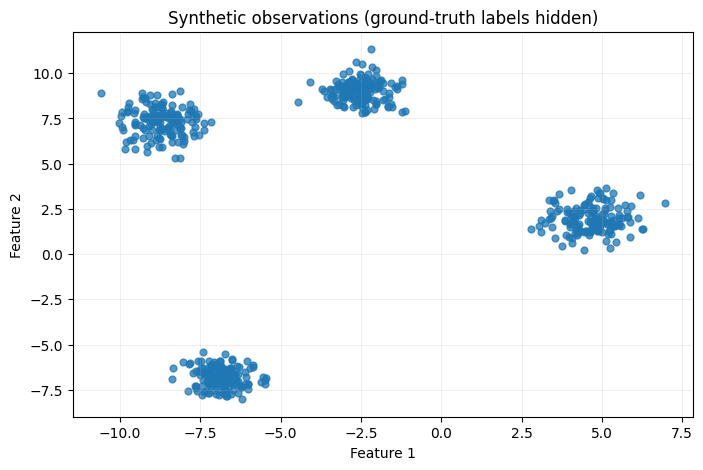

Feature matrix shape: (600, 2)


In [2]:
X, y_true = make_blobs(
    n_samples=600,
    centers=4,
    cluster_std=[0.60, 0.75, 0.55, 0.70],
    random_state=RANDOM_STATE,
)

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=24, alpha=0.75)
plt.title("Synthetic observations (ground-truth labels hidden)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(alpha=0.2)
plt.show()

print("Feature matrix shape:", X.shape)

## 5. Simplified Mean Shift from scratch

This educational version uses Gaussian weights and iteratively moves each observation. It then greedily merges converged points that are close to one another. It is intentionally not optimized; use a small dataset because the repeated pairwise distance calculations can be expensive.

In [3]:
def mean_shift_from_scratch(X, bandwidth, max_iter=100, tol=1e-3,
                            merge_distance=None):
    # Validate the input.
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[0] == 0:
        raise ValueError("X must be a non-empty 2D array.")
    if bandwidth <= 0:
        raise ValueError("bandwidth must be positive.")
    if merge_distance is None:
        merge_distance = bandwidth / 2

    converged_points = []

    for start in X:
        point = start.copy()

        for _ in range(max_iter):
            # Squared Euclidean distance from the current point to every observation.
            squared_distances = np.sum((X - point) ** 2, axis=1)

            # Gaussian kernel weights give more influence to nearby observations.
            weights = np.exp(-squared_distances / (2 * bandwidth ** 2))
            weight_sum = weights.sum()
            if weight_sum <= 0 or not np.isfinite(weight_sum):
                break

            # Update the point to the weighted mean.
            updated_point = np.sum(X * weights[:, None], axis=0) / weight_sum
            movement = np.linalg.norm(updated_point - point)
            point = updated_point

            # Stop when the update is sufficiently small.
            if movement < tol:
                break

        converged_points.append(point)

    converged_points = np.asarray(converged_points)

    # Greedily merge nearby converged points into representative modes.
    centers = []
    for point in converged_points:
        if not centers:
            centers.append(point.copy())
            continue
        distances = np.linalg.norm(np.asarray(centers) - point, axis=1)
        if distances.min() > merge_distance:
            centers.append(point.copy())

    centers = np.asarray(centers)

    # Assign each original observation to its nearest estimated mode.
    distances = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
    labels = distances.argmin(axis=1)
    return labels, centers

### Run the educational implementation

A subset keeps the demonstration manageable on modest hardware.

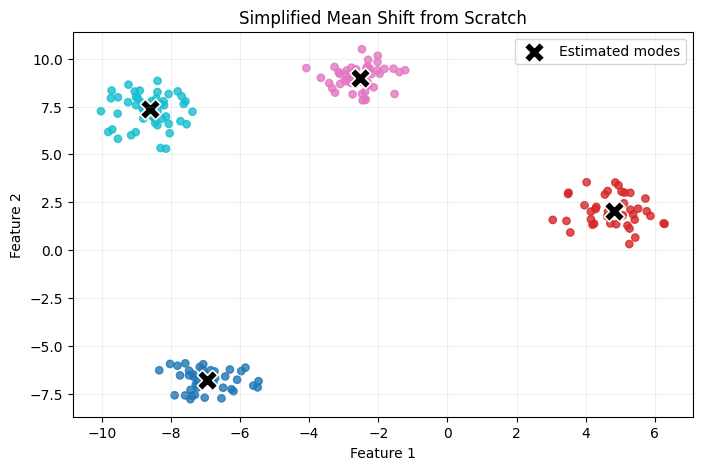

Estimated clusters: 4
Runtime: 0.04 seconds


In [4]:
X_small = X[:180]

start_time = time.perf_counter()
custom_labels, custom_centers = mean_shift_from_scratch(
    X_small, bandwidth=1.5, max_iter=80, tol=1e-3
)
custom_seconds = time.perf_counter() - start_time

plt.figure(figsize=(8, 5))
plt.scatter(X_small[:, 0], X_small[:, 1], c=custom_labels,
            cmap="tab10", s=28, alpha=0.8)
plt.scatter(custom_centers[:, 0], custom_centers[:, 1],
            marker="X", s=220, c="black", edgecolors="white",
            linewidths=1.2, label="Estimated modes")
plt.title("Simplified Mean Shift from Scratch")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Estimated clusters:", len(custom_centers))
print(f"Runtime: {custom_seconds:.2f} seconds")

**Implementation caveat:** this implementation teaches the update rule, not a production-grade clustering pipeline. Greedy mode merging can be order-dependent, and nearest-center assignment is a simplification. For applied work, use and validate the maintained library implementation.

## 6. Mean Shift with Scikit-learn

The main estimator is `sklearn.cluster.MeanShift`.

Key parameters:
- `bandwidth`: neighborhood scale; if omitted, it is estimated from the data.
- `seeds`: optional initial candidate centers.
- `bin_seeding`: use discretized seeds to reduce computation in suitable datasets.
- `min_bin_freq`: minimum observations in a seed bin when bin seeding is enabled.
- `cluster_all`: if `False`, points outside discovered neighborhoods can be labelled `-1`.
- `max_iter`: maximum iterations per seed.
- `n_jobs`: parallel jobs for neighbor computations where supported.

In [5]:
estimated_bandwidth = estimate_bandwidth(
    X, quantile=0.2, n_samples=min(300, len(X)),
    random_state=RANDOM_STATE
)
print("Estimated bandwidth:", estimated_bandwidth)

# Guard against an unusable estimate on unusual datasets.
if not np.isfinite(estimated_bandwidth) or estimated_bandwidth <= 0:
    estimated_bandwidth = 1.0
    warnings.warn("Invalid estimate; using bandwidth=1.0 for demonstration.")

mean_shift = MeanShift(
    bandwidth=estimated_bandwidth,
    bin_seeding=True,
    cluster_all=True,
    max_iter=300,
    n_jobs=-1,
)

start_time = time.perf_counter()
labels_ms = mean_shift.fit_predict(X)
runtime_ms = time.perf_counter() - start_time
centers_ms = mean_shift.cluster_centers_

print("Number of clusters:", len(np.unique(labels_ms)))
print("Cluster centers shape:", centers_ms.shape)
print(f"Runtime: {runtime_ms:.4f} seconds")
print("First 15 labels:", labels_ms[:15])

Estimated bandwidth: 1.5435247566879697
Number of clusters: 4
Cluster centers shape: (4, 2)
Runtime: 8.3377 seconds
First 15 labels: [0 0 0 0 3 3 0 1 0 0 1 3 2 2 1]


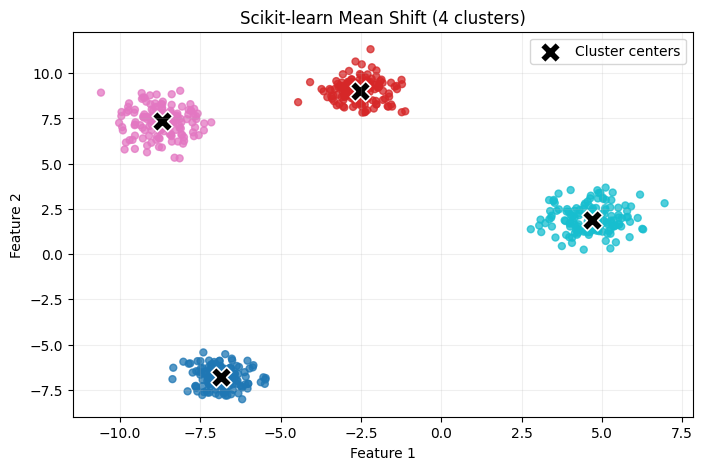

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels_ms, cmap="tab10", s=25, alpha=0.75)
plt.scatter(centers_ms[:, 0], centers_ms[:, 1], marker="X", s=220,
            c="black", edgecolors="white", linewidths=1.2,
            label="Cluster centers")
plt.title(f"Scikit-learn Mean Shift ({len(centers_ms)} clusters)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [7]:
cluster_sizes = (
    pd.Series(labels_ms, name="cluster")
    .value_counts()
    .sort_index()
    .rename("n_samples")
    .to_frame()
)
display(cluster_sizes)

,n_samples
cluster,
0,150
1,150
2,150
3,150


## 7. Bandwidth sensitivity

Bandwidth is often the most consequential Mean Shift hyperparameter. The following experiment fits the model with several values and records the number of clusters and runtime.

Bandwidth depends on feature scale. Standardize features when their units or ranges differ substantially.

In [8]:
bandwidth_candidates = [
    max(0.25, estimated_bandwidth * factor)
    for factor in [0.5, 0.75, 1.0, 1.5, 2.0]
]

bandwidth_rows = []
bandwidth_labels = {}

for bandwidth in bandwidth_candidates:
    model = MeanShift(
        bandwidth=bandwidth, bin_seeding=True,
        cluster_all=True, max_iter=300, n_jobs=-1
    )
    t0 = time.perf_counter()
    labels = model.fit_predict(X)
    elapsed = time.perf_counter() - t0

    bandwidth_labels[bandwidth] = labels
    bandwidth_rows.append({
        "bandwidth": bandwidth,
        "n_clusters": len(np.unique(labels)),
        "runtime_seconds": elapsed,
    })

bandwidth_results = pd.DataFrame(bandwidth_rows)
display(bandwidth_results.round(4))

,bandwidth,n_clusters,runtime_seconds
0,0.7718,8,0.2593
1,1.1576,4,0.0852
2,1.5435,4,0.0636
3,2.3153,4,0.0488
4,3.0870,4,0.0471


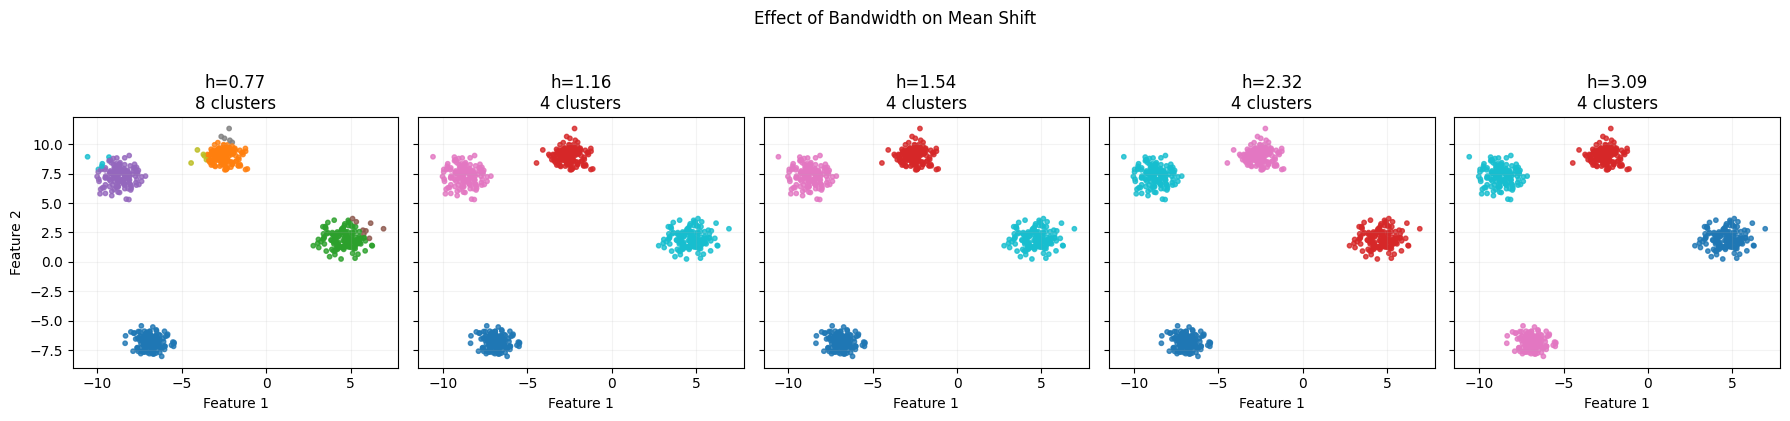

In [9]:
fig, axes = plt.subplots(1, len(bandwidth_candidates), figsize=(18, 4),
                         sharex=True, sharey=True)
for ax, bandwidth in zip(axes, bandwidth_candidates):
    labels = bandwidth_labels[bandwidth]
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=10, alpha=0.8)
    ax.set_title(f"h={bandwidth:.2f}\n{len(np.unique(labels))} clusters")
    ax.set_xlabel("Feature 1")
    ax.grid(alpha=0.15)
axes[0].set_ylabel("Feature 2")
fig.suptitle("Effect of Bandwidth on Mean Shift", y=1.04)
plt.tight_layout()
plt.show()

**Interpretation prompt:** Which bandwidth recovers the broad groups without fragmenting them? Do not choose a bandwidth solely because it produces an expected cluster count; use domain knowledge and validation where available.

## 8. Compare Mean Shift, K-Means, and DBSCAN

- **K-Means:** requires the number of clusters; often works well for compact, roughly spherical groups.
- **Mean Shift:** seeks modes of a smoothed density estimate; bandwidth controls granularity.
- **DBSCAN:** finds density-connected groups and can label sparse observations as noise.

No algorithm is universally best. Cluster geometry and the scientific objective determine which method is appropriate.

In [10]:
X_compare, y_compare_true = make_blobs(
    n_samples=500, centers=4, cluster_std=0.65,
    random_state=RANDOM_STATE
)
compare_bw = estimate_bandwidth(
    X_compare, quantile=0.2,
    n_samples=min(300, len(X_compare)),
    random_state=RANDOM_STATE
)
if not np.isfinite(compare_bw) or compare_bw <= 0:
    compare_bw = 1.0

models = {
    "Mean Shift": MeanShift(
        bandwidth=compare_bw, bin_seeding=True, n_jobs=-1
    ),
    "K-Means": KMeans(
        n_clusters=4, n_init=10, random_state=RANDOM_STATE
    ),
    "DBSCAN": DBSCAN(eps=0.8, min_samples=5),
}

comparison_labels = {}
comparison_rows = []

for name, model in models.items():
    t0 = time.perf_counter()
    labels = model.fit_predict(X_compare)
    elapsed = time.perf_counter() - t0
    comparison_labels[name] = labels

    n_clusters = len(set(labels) - {-1})
    n_noise = int(np.sum(labels == -1))
    comparison_rows.append({
        "algorithm": name,
        "clusters_excluding_noise": n_clusters,
        "noise_points": n_noise,
        "runtime_seconds": elapsed,
        "ARI_vs_ground_truth": adjusted_rand_score(y_compare_true, labels),
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(4))

,algorithm,clusters_excluding_noise,noise_points,runtime_seconds,ARI_vs_ground_truth
0,Mean Shift,4,0,0.0596,1.0000
1,K-Means,4,0,0.0237,1.0000
2,DBSCAN,4,1,0.0037,0.9973


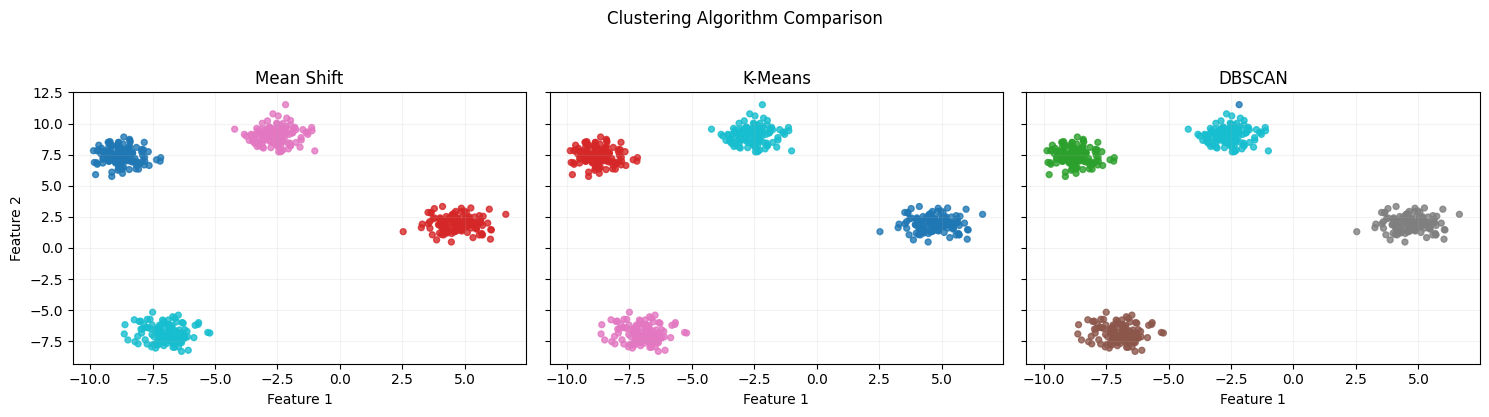

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (name, labels) in zip(axes, comparison_labels.items()):
    ax.scatter(X_compare[:, 0], X_compare[:, 1],
               c=labels, cmap="tab10", s=18, alpha=0.8)
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.grid(alpha=0.15)
axes[0].set_ylabel("Feature 2")
fig.suptitle("Clustering Algorithm Comparison", y=1.03)
plt.tight_layout()
plt.show()

## 9. Evaluation metrics

### Internal metrics
- **Silhouette Score:** ranges from -1 to 1; higher values often indicate better separation and cohesion. It requires at least two clusters and fewer clusters than samples.
- **Davies–Bouldin Index:** lower is generally better.
- **Calinski–Harabasz Index:** higher is generally better.

### External metric
- **Adjusted Rand Index (ARI):** compares cluster assignments with reference labels. It is appropriate for synthetic experiments or datasets with trusted labels. Most real unsupervised problems do not have ground-truth labels.

Metrics capture different properties; none proves scientific validity.

In [12]:
def safe_internal_metrics(X_data, labels):
    # Exclude DBSCAN noise points before calculating internal metrics.
    labels = np.asarray(labels)
    keep = labels != -1
    X_eval = X_data[keep]
    labels_eval = labels[keep]
    n_clusters = len(np.unique(labels_eval))

    # These metrics are undefined with fewer than 2 clusters or one cluster per point.
    if n_clusters < 2 or n_clusters >= len(labels_eval):
        return {
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan,
        }

    return {
        "silhouette": silhouette_score(X_eval, labels_eval),
        "davies_bouldin": davies_bouldin_score(X_eval, labels_eval),
        "calinski_harabasz": calinski_harabasz_score(X_eval, labels_eval),
    }

metric_rows = []
for name, labels in comparison_labels.items():
    metric_rows.append({
        "algorithm": name,
        **safe_internal_metrics(X_compare, labels),
    })

display(pd.DataFrame(metric_rows).round(4))

,algorithm,silhouette,davies_bouldin,calinski_harabasz
0,Mean Shift,0.8652,0.1896,13534.3434
1,K-Means,0.8652,0.1896,13534.3434
2,DBSCAN,0.8660,0.1885,13690.8327


## 10. Bioinformatics mini-project: synthetic gene expression

This section creates a **synthetic** gene-expression matrix with three simulated patient groups. It demonstrates a workflow, not a clinical discovery. The reference group labels are used only after clustering for evaluation.

Workflow:
1. Generate simulated expression features.
2. Standardize genes because Mean Shift uses distances.
3. Estimate a candidate bandwidth.
4. Fit Mean Shift.
5. Compare with simulated reference groups using ARI.
6. Visualize the high-dimensional data in two dimensions using PCA.

In [13]:
rng = np.random.default_rng(RANDOM_STATE)

n_patients = 240
n_genes = 40
n_groups = 3
patients_per_group = n_patients // n_groups

# Simulate group-specific expression patterns.
group_centers = rng.normal(0, 1, size=(n_groups, n_genes))
for group in range(n_groups):
    # Add stronger signal to five genes per simulated group.
    start = group * 5
    group_centers[group, start:start + 5] += 2.5

expression_blocks = []
bio_true_labels = []
for group in range(n_groups):
    block = group_centers[group] + rng.normal(
        0, 0.8, size=(patients_per_group, n_genes)
    )
    expression_blocks.append(block)
    bio_true_labels.extend([group] * patients_per_group)

X_expression = np.vstack(expression_blocks)
bio_true_labels = np.asarray(bio_true_labels)
gene_names = [f"Gene_{i+1:02d}" for i in range(n_genes)]
patient_ids = [f"Patient_{i+1:03d}" for i in range(n_patients)]

expression_df = pd.DataFrame(
    X_expression, index=patient_ids, columns=gene_names
)
expression_df.index.name = "Patient_ID"

display(expression_df.iloc[:5, :8].round(2))
print("Expression matrix shape:", expression_df.shape)

,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06,Gene_07,Gene_08
Patient_ID,,,,,,,,
Patient_001,1.99,1.60,3.43,4.53,1.22,-1.02,1.30,-1.27
Patient_002,2.03,0.88,4.95,2.78,1.22,-2.02,0.87,-0.01
Patient_003,3.07,2.59,3.32,3.96,-1.09,-1.34,-0.55,-1.29
Patient_004,2.10,1.38,1.84,2.27,2.25,-2.33,-0.75,1.15
Patient_005,3.19,0.06,3.99,3.80,-0.34,-1.68,0.34,-0.27


Expression matrix shape: (240, 40)


In [14]:
# Standardize each gene so that different scales do not dominate Euclidean distance.
scaler = StandardScaler()
X_expression_scaled = scaler.fit_transform(expression_df)

bio_bandwidth = estimate_bandwidth(
    X_expression_scaled,
    quantile=0.2,
    n_samples=min(200, n_patients),
    random_state=RANDOM_STATE,
)
if not np.isfinite(bio_bandwidth) or bio_bandwidth <= 0:
    bio_bandwidth = 1.0
    warnings.warn("Invalid bandwidth estimate; using 1.0 for demonstration.")

bio_model = MeanShift(
    bandwidth=bio_bandwidth, bin_seeding=True,
    cluster_all=True, max_iter=300, n_jobs=-1
)
bio_labels = bio_model.fit_predict(X_expression_scaled)

print("Estimated bandwidth:", round(bio_bandwidth, 4))
print("Discovered clusters:", len(np.unique(bio_labels)))
print("ARI vs simulated groups:", round(
    adjusted_rand_score(bio_true_labels, bio_labels), 4
))

Estimated bandwidth: 6.6616
Discovered clusters: 1
ARI vs simulated groups: 0.0


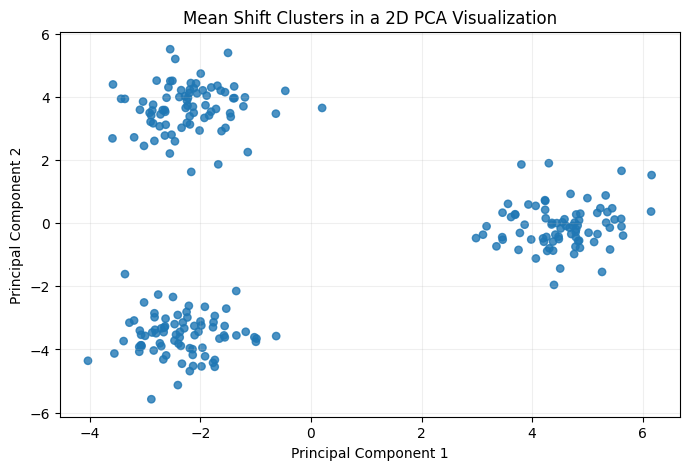

In [15]:
from sklearn.decomposition import PCA

# PCA is used for visualization only; clustering used all standardized genes.
X_expression_2d = PCA(
    n_components=2, random_state=RANDOM_STATE
).fit_transform(X_expression_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_expression_2d[:, 0], X_expression_2d[:, 1],
    c=bio_labels, cmap="tab10", s=28, alpha=0.8
)
plt.title("Mean Shift Clusters in a 2D PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.2)
plt.show()

### Bioinformatics interpretation and safeguards

- A cluster is a computational grouping, not automatically a cancer subtype.
- Real studies must consider batch effects, missingness, normalization, and confounding.
- For downstream predictive evaluation, fit transformations and select parameters using development data only to avoid leakage.
- Assess stability under resampling and alternative preprocessing choices.
- Validate biological claims with independent cohorts, pathway analyses, clinical context, and suitable statistical tests.
- In high-dimensional expression data, Euclidean distances may be unstable; feature selection or dimensionality reduction may help but must be justified and validated.

## 11. Computational complexity and practical guidance

A naive implementation repeatedly computes distances from candidate points to observations. Runtime can become substantial as sample count and feature dimension increase. Exact runtime depends on bandwidth, seed selection, and neighbor-search behavior.

### Practical checklist
- Standardize features when units or ranges differ.
- Estimate bandwidth on a representative sample for large datasets.
- Inspect cluster sizes and centers, not just the cluster count.
- Test several bandwidths and document the selection rationale.
- Consider `bin_seeding=True` when appropriate.
- Benchmark runtime and memory on representative data.
- For very large datasets, assess whether Mean Shift is the right method.
- Treat clustering output as a hypothesis that needs validation.

## 12. Exercises

### Beginner
1. Change `quantile` in `estimate_bandwidth` to `0.1`, `0.3`, and `0.5`. How does the estimate change?
2. Fit Mean Shift with three manually selected bandwidths and plot the results.
3. Print the number of samples in each cluster.

### Intermediate
4. Generate two-moon data with `make_moons`. Compare Mean Shift, K-Means, and DBSCAN.
5. Create features with different scales and compare results before and after standardization.
6. Evaluate stability by repeatedly sampling 80% of observations and comparing assignments on a common subset.

### Advanced
7. Change the kernel weighting scheme in the educational implementation and discuss the implications.
8. Investigate how high-dimensional noise features affect assignments.
9. Design a reproducible analysis plan for real gene-expression data, including preprocessing, bandwidth selection, stability analysis, and external validation.

**Challenge:** Write a short report explaining why your selected bandwidth is defensible. Include at least one limitation and one alternative algorithm.

## 13. Key takeaways

- Mean Shift is a mode-seeking clustering method based on local density.
- It does not require the number of clusters in advance.
- Bandwidth strongly controls the granularity of the result.
- A from-scratch implementation helps explain the update rule; scikit-learn is preferable for applied work.
- Compare methods using metrics, visual inspection, stability checks, and domain knowledge.
- In bioinformatics, clusters are hypotheses—not clinical conclusions.

### Official references
- [Scikit-learn Mean Shift API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MeanShift.html)
- [Scikit-learn `estimate_bandwidth` API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.estimate_bandwidth.html)
- [Clustering user guide](https://scikit-learn.org/stable/modules/clustering.html)
- [Clustering performance evaluation](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation)